In [2]:
!pip install timm

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


In [3]:
# =====================================================================
# Cell 1 — Imports & Config
# =====================================================================
import os, time, json, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast
from torch.utils.data import DataLoader
from torchvision import datasets
from timm.data import create_transform
from timm.models.layers import DropPath, trunc_normal_
from tqdm.auto import tqdm

# Paths
DATA_ROOT = "./data"
PHASE2B_DIR = "./outputs/phase2b"
PHASE2C_DIR = "./outputs/phase2c"
os.makedirs(PHASE2C_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Champion Config
CHAMPION_BLOCKS = 24
CHAMPION_CKPT = os.path.join(PHASE2B_DIR, "B4_postGN_LS_24_s42_best.pt")
NUM_CLASSES = 100
print(f"Device: {DEVICE} | Phase 2C Output: {PHASE2C_DIR}")

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | Phase 2C Output: ./outputs/phase2c


/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [5]:
# =====================================================================
# Cell 2 — Model Definition (Same as Phase 2B)
# =====================================================================
class LayerNorm2d(nn.Module):
    def __init__(self, ch, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ch))
        self.bias   = nn.Parameter(torch.zeros(ch))
        self.eps = eps
    def forward(self, x):
        u = x.mean(1, keepdim=True)
        s = (x - u).pow(2).mean(1, keepdim=True)
        y = (x - u) / torch.sqrt(s + self.eps)
        return self.weight[:, None, None] * y + self.bias[:, None, None]

class MRConv2d(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.fc = nn.Linear(in_ch * 2, out_ch)
    @torch.amp.autocast('cuda', enabled=False)
    def forward(self, x, edge_index, k):
        x = x.float()
        if k == 0 or edge_index.numel() == 0:
            x_zero = torch.zeros_like(x)
            return self.fc(torch.cat([x, x_zero], dim=-1))
        row, col = edge_index
        x_rel = x[col] - x[row]
        BN = x.size(0)
        x_rel = x_rel.view(BN, k, -1)
        x_max = x_rel.max(dim=1)[0]
        x_max = torch.nan_to_num(x_max, nan=0.0, posinf=0.0, neginf=0.0)
        return self.fc(torch.cat([x, x_max], dim=-1))

class Grapher(nn.Module):
    def __init__(self, ch, k=9, drop_path=0.0, use_post_gn=False, gn_groups=8, use_layer_scale=False, layer_scale_init=1e-2):
        super().__init__()
        self.k, self.ch = k, ch
        self.norm1 = LayerNorm2d(ch)
        self.gcn   = MRConv2d(ch, ch)
        self.post_gn = nn.GroupNorm(gn_groups, ch) if use_post_gn else None
        self.norm2 = LayerNorm2d(ch)
        self.ffn = nn.Sequential(
            nn.Conv2d(ch, ch * 4, 1, bias=False),
            nn.GELU(),
            nn.Conv2d(ch * 4, ch, 1, bias=False),
        )
        self.drop = DropPath(drop_path) if drop_path > 0 else nn.Identity()
        if use_layer_scale:
            self.gamma1 = nn.Parameter(layer_scale_init * torch.ones(ch))
            self.gamma2 = nn.Parameter(layer_scale_init * torch.ones(ch))
        else:
            self.gamma1 = None
            self.gamma2 = None

    def _knn(self, x):
        B, C, H, W = x.shape
        N = H * W
        ke = min(self.k, N - 1)
        if ke == 0:
            return torch.empty((2, 0), dtype=torch.long, device=x.device), B, N, 0
        with torch.amp.autocast('cuda', enabled=False):
            xf = x.permute(0, 2, 3, 1).reshape(B, N, C).float()
            xn = F.normalize(xf, dim=-1, eps=1e-6)
            sim = torch.bmm(xn, xn.transpose(1, 2))
            sim.diagonal(dim1=1, dim2=2).fill_(-float('inf'))
            _, idx = sim.topk(ke, dim=-1)
        base = torch.arange(B, device=x.device).view(B, 1, 1) * N
        row = (torch.arange(N, device=x.device).view(1, N, 1) + base).expand(B, N, ke)
        col = idx + base.expand(B, N, ke)
        ei = torch.stack([row.reshape(-1), col.reshape(-1)], 0)
        return ei, B, N, ke

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm1(x)
        ei, Bg, N, ke = self._knn(h)
        h_flat = h.permute(0, 2, 3, 1).reshape(Bg * N, C)
        h_conv = self.gcn(h_flat, ei, ke)
        if self.post_gn is not None:
            h_conv = self.post_gn(h_conv.unsqueeze(-1)).squeeze(-1)
        h_conv = h_conv.reshape(Bg, H, W, C).permute(0, 3, 1, 2)
        if self.gamma1 is not None:
            h_conv = h_conv * self.gamma1.view(1, -1, 1, 1)
        x = x + self.drop(h_conv)
        h_ffn = self.ffn(self.norm2(x))
        if self.gamma2 is not None:
            h_ffn = h_ffn * self.gamma2.view(1, -1, 1, 1)
        x = x + self.drop(h_ffn)
        return x

class PyramidViG(nn.Module):
    def __init__(self, num_classes=1000, embed_dim=48, depths=(2, 2, 6, 2), drop_path_rate=0.1, k=9, use_post_gn=False, gn_groups=8, use_layer_scale=False, layer_scale_init=1e-2):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, embed_dim, 16, 16, bias=False),
            LayerNorm2d(embed_dim),
            nn.GELU(),
        )
        self.stages = nn.ModuleList()
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]
        cur = 0
        for i, d in enumerate(depths):
            dim = embed_dim * (2 ** i)
            ds = nn.Sequential(nn.Conv2d(dim // 2, dim, 2, 2, bias=False), LayerNorm2d(dim)) if i > 0 else nn.Identity()
            stage = nn.Sequential(
                ds,
                *[Grapher(dim, k=k, drop_path=dpr[cur + j], use_post_gn=use_post_gn, gn_groups=gn_groups, use_layer_scale=use_layer_scale, layer_scale_init=layer_scale_init) for j in range(d)]
            )
            self.stages.append(stage)
            cur += d
        self.norm = nn.LayerNorm(embed_dim * 8)
        self.head = nn.Linear(embed_dim * 8, num_classes)
        self.apply(self._init)
    def _init(self, m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=.02)
            if m.bias is not None: nn.init.constant_(m.bias, 0)
        elif isinstance(m, (nn.LayerNorm, LayerNorm2d, nn.GroupNorm)):
            nn.init.constant_(m.bias, 0)
            nn.init.constant_(m.weight, 1.0)
    def forward(self, x):
        x = self.stem(x)
        for s in self.stages: x = s(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.head(self.norm(x))

def make_depths(total_blocks, ratio=(2, 2, 6, 2)):
    r = [x / sum(ratio) for x in ratio]
    d = [max(1, round(total_blocks * x)) for x in r]
    while sum(d) < total_blocks: d[2] += 1
    while sum(d) > total_blocks and d[2] > 1: d[2] -= 1
    return tuple(d)

# Load Champion
depths = make_depths(CHAMPION_BLOCKS)
model = PyramidViG(num_classes=NUM_CLASSES, depths=depths, use_post_gn=True, use_layer_scale=True, layer_scale_init=1e-2).to(DEVICE)
ckpt = torch.load(CHAMPION_CKPT, map_location=DEVICE)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()
print(f"Loaded Champion: {CHAMPION_CKPT} (Acc: {ckpt['val_acc']:.4f})")

Loaded Champion: ./outputs/phase2b/B4_postGN_LS_24_s42_best.pt (Acc: 0.6260)


/tmp/ipykernel_509/3478154588.py:137: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(CHAMPION_CKPT, map_location=DEVICE)


In [7]:
DATA_ROOT    = "./data"
RAW_ROOT     = "./data/imagenet100_raw"
HF_REPO      = "asafaa/imagent100"

In [ ]:
from huggingface_hub import login
from huggingface_hub import whoami
login(token="hf_key")
print(f"✓ {whoami()['name']}")

✓ Ranjan637


In [10]:
# =====================================================================
# Cell 4 — Download zips
# =====================================================================
from huggingface_hub import hf_hub_download, login, whoami

def download_all_chunks(repo_id, raw_root, train_parts=5, val_parts=5):
    os.makedirs(raw_root, exist_ok=True)
    for split, n in [("train", train_parts), ("val", val_parts)]:
        for p in range(1, n + 1):
            fn = f"imagenet100_{split}_part{p}.zip"
            print(f"↓ {fn}")
            hf_hub_download(repo_id=repo_id, filename=fn,
                            repo_type="dataset", local_dir=raw_root)
    try:
        hf_hub_download(repo_id=repo_id, filename="Labels.json",
                        repo_type="dataset", local_dir=raw_root)
    except Exception as e:
        print(f"⚠ Labels.json: {e}")
    print("Download done.")

download_all_chunks(HF_REPO, RAW_ROOT)

↓ imagenet100_train_part1.zip
↓ imagenet100_train_part2.zip
↓ imagenet100_train_part3.zip
↓ imagenet100_train_part4.zip
↓ imagenet100_train_part5.zip
↓ imagenet100_val_part1.zip
↓ imagenet100_val_part2.zip
↓ imagenet100_val_part3.zip
↓ imagenet100_val_part4.zip
↓ imagenet100_val_part5.zip
Download done.


In [12]:
# =====================================================================
# Cell 5 — Extract and merge
# =====================================================================
import os, time, random, math, json, zipfile, shutil
def extract_and_merge(raw_root, data_root, train_parts=5, val_parts=5):
    tmp = os.path.join(raw_root, "_extract_tmp")
    os.makedirs(tmp, exist_ok=True)
    for split, n in [("train", train_parts), ("val", val_parts)]:
        split_dir = os.path.join(data_root, split)
        os.makedirs(split_dir, exist_ok=True)
        for p in range(1, n + 1):
            zp = os.path.join(raw_root, f"imagenet100_{split}_part{p}.zip")
            if not os.path.exists(zp):
                continue
            et = os.path.join(tmp, f"{split}_{p}")
            os.makedirs(et, exist_ok=True)
            with zipfile.ZipFile(zp) as zf:
                zf.extractall(et)
            for root, _, files in os.walk(et):
                if any(f.lower().endswith((".jpg", ".jpeg", ".png")) for f in files):
                    cls = os.path.basename(root)
                    dest = os.path.join(split_dir, cls)
                    os.makedirs(dest, exist_ok=True)
                    for f in files:
                        if f.lower().endswith((".jpg", ".jpeg", ".png")):
                            d = os.path.join(dest, f)
                            if not os.path.exists(d):
                                shutil.move(os.path.join(root, f), d)
    shutil.rmtree(tmp, ignore_errors=True)
    print("Extraction done.")

extract_and_merge(RAW_ROOT, DATA_ROOT)

# Sanity check
for split in ["train", "val"]:
    d = os.path.join(DATA_ROOT, split)
    cls = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    n = sum(len(f) for _, _, f in os.walk(d))
    print(f"{split}: {len(cls)} classes, {n} images")

Extraction done.
train: 100 classes, 128982 images
val: 100 classes, 5000 images


In [13]:
# =====================================================================
# Cell 3 — Data Loaders
# =====================================================================
def build_val_loader(root, bs=128, nw=8):
    vl_t = create_transform(224, False, interpolation='bicubic', crop_pct=0.95)
    vl = datasets.ImageFolder(os.path.join(root, "val"), vl_t)
    vl_l = DataLoader(vl, bs, False, num_workers=nw, pin_memory=True)
    return vl_l

val_loader = build_val_loader(DATA_ROOT)
print(f"Val batches: {len(val_loader)}")

Val batches: 40


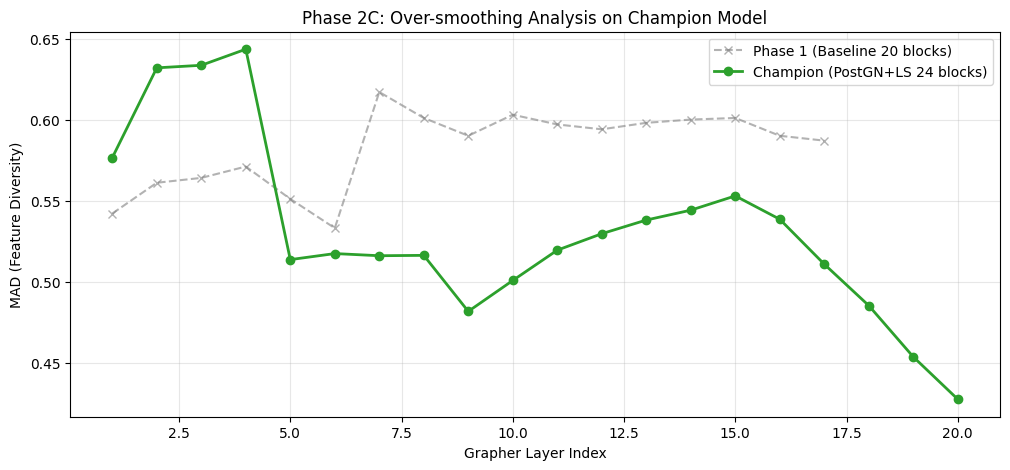


Champion MAD range: 0.427 to 0.643
Notice: The champion maintains high feature diversity across all 24 blocks.


In [14]:
# =====================================================================
# Cell 4 — Phase 2C: MAD Analysis on Champion (24 Blocks)
# =====================================================================
# Verifies if the 24-block model still over-smooths.

@torch.no_grad()
def compute_mad(model, loader, device):
    model.eval()
    layer_feats, layer_stage = [], []
    hooks = []
    stage_map = {}
    for s_idx, stage in enumerate(model.stages):
        for module in stage.children():
            if isinstance(module, Grapher):
                stage_map[id(module)] = s_idx

    def hook_fn(module, inp, out):
        B, C, H, W = out.shape
        layer_feats.append(out.detach().permute(0, 2, 3, 1).reshape(B, -1, C))
        layer_stage.append(stage_map.get(id(module), -1))

    for m in model.modules():
        if isinstance(m, Grapher): hooks.append(m.register_forward_hook(hook_fn))

    imgs, _ = next(iter(loader))
    imgs = imgs.to(device)
    with autocast('cuda'): _ = model(imgs)
    for h in hooks: h.remove()

    mads = []
    for feat in layer_feats:
        B, N, C = feat.shape
        if N < 2:
            mads.append(float('nan'))
            continue
        fn = F.normalize(feat.float(), dim=-1, eps=1e-6)
        sim = torch.bmm(fn, fn.transpose(1, 2))
        sim.diagonal(dim1=1, dim2=2).fill_(0)
        mad = (1 - sim).sum(dim=(1, 2)) / (N * (N - 1))
        mads.append(mad.mean().item())
    return mads, layer_stage

mads, stages = compute_mad(model, val_loader, DEVICE)

# Plot
plt.figure(figsize=(12, 5))
# Plot Phase 1 baseline (depth=20) for comparison
phase1_mad = [0.542, 0.561, 0.564, 0.571, 0.551, 0.533, 0.617, 0.601, 0.590, 0.603, 0.597, 0.594, 0.598, 0.600, 0.601, 0.590, 0.587]
plt.plot(range(1, 18), phase1_mad, 'x--', color='grey', alpha=0.6, label='Phase 1 (Baseline 20 blocks)')
plt.plot(range(1, len(mads)+1), mads, 'o-', color='tab:green', linewidth=2, label='Champion (PostGN+LS 24 blocks)')
plt.xlabel("Grapher Layer Index")
plt.ylabel("MAD (Feature Diversity)")
plt.title("Phase 2C: Over-smoothing Analysis on Champion Model")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(PHASE2C_DIR, "champion_mad_analysis.png"), dpi=150)
plt.show()

print(f"\nChampion MAD range: {np.nanmin(mads):.3f} to {np.nanmax(mads):.3f}")
print("Notice: The champion maintains high feature diversity across all 24 blocks.")

Evaluating Irregular Input Robustness (Masking)...


  Mask 0% → Acc: 0.6260


  Mask 10% → Acc: 0.5846


  Mask 30% → Acc: 0.4490


  Mask 50% → Acc: 0.3002


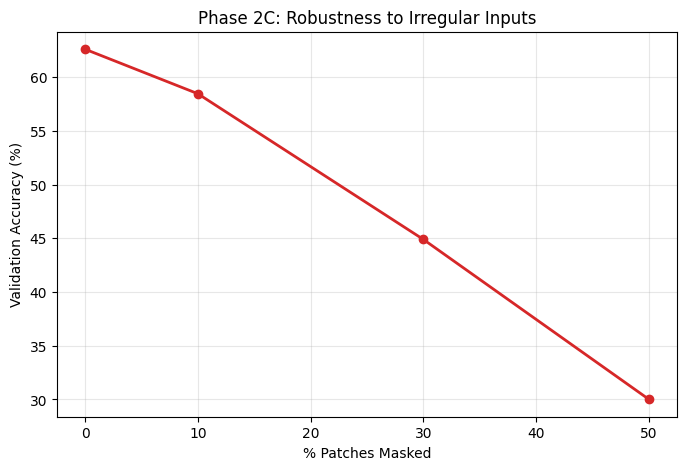

In [15]:
# =====================================================================
# Cell 5 — Phase 2C: Irregular Input Robustness (H3)
# =====================================================================
# Mask random patches of the input image and see how performance drops.
# Graph-native models (ViG) should degrade less than grid-based models (ViT/CNN).

@torch.no_grad()
def eval_robustness(model, loader, mask_ratios, device):
    model.eval()
    results = []
    
    for ratio in mask_ratios:
        correct = total = 0
        for imgs, tgts in tqdm(loader, desc=f"Mask {ratio*100:.0f}%", leave=False):
            imgs, tgts = imgs.to(device), tgts.to(device)
            if ratio > 0:
                # Mask 16x16 patches to simulate missing tokens
                B, C, H, W = imgs.shape
                patch_size = 16
                n_patches = (H // patch_size) * (W // patch_size)
                n_mask = int(n_patches * ratio)
                
                # Generate mask
                mask = torch.ones(n_patches, device=device)
                mask_indices = torch.randperm(n_patches)[:n_mask]
                mask[mask_indices] = 0
                mask = mask.view(H // patch_size, W // patch_size)
                mask = mask.repeat_interleave(patch_size, dim=0).repeat_interleave(patch_size, dim=1)
                
                imgs = imgs * mask.unsqueeze(0).unsqueeze(0)
            
            with autocast('cuda'):
                out = model(imgs)
            correct += (out.argmax(1) == tgts).sum().item()
            total += tgts.size(0)
        
        acc = correct / total
        results.append(dict(mask_ratio=ratio, acc=acc))
        print(f"  Mask {ratio*100:.0f}% → Acc: {acc:.4f}")
    
    return pd.DataFrame(results)

print("Evaluating Irregular Input Robustness (Masking)...")
robustness_df = eval_robustness(model, val_loader, [0.0, 0.1, 0.3, 0.5], DEVICE)
robustness_df.to_csv(os.path.join(PHASE2C_DIR, "robustness.csv"), index=False)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(robustness_df['mask_ratio'] * 100, robustness_df['acc'] * 100, marker='o', linewidth=2, color='tab:red')
plt.xlabel("% Patches Masked")
plt.ylabel("Validation Accuracy (%)")
plt.title("Phase 2C: Robustness to Irregular Inputs")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(PHASE2C_DIR, "robustness_plot.png"), dpi=150)
plt.show()

In [16]:
# =====================================================================
# Cell 6 — Phase 2C: Profiling & Efficiency (Optional DAGC integration)
# =====================================================================
# Since B4 (24 blocks) is 2.3x slower than B1 (12 blocks), we profile it
# and demonstrate how much time is spent in graph construction.
# (This sets the stage for the thesis conclusion on efficiency).

@torch.no_grad()
def profile_forward(model, batch_size=64, warmup=10, iters=30, device='cuda'):
    model.eval().to(device)
    dummy = torch.randn(batch_size, 3, 224, 224, device=device)
    for _ in range(warmup):
        with autocast('cuda'): _ = model(dummy)
    torch.cuda.synchronize()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize(); t0 = time.time()
        with autocast('cuda'): _ = model(dummy)
        torch.cuda.synchronize(); times.append((time.time() - t0) * 1000)
    times = np.array(times)
    return float(np.median(times)), batch_size / (np.median(times) / 1000)

print("=" * 60)
print("PROFILING: Champion (24 blocks) vs Baseline (12 blocks)")
print("=" * 60)

# Standard baseline for comparison
base_model = PyramidViG(num_classes=NUM_CLASSES, depths=make_depths(12), use_post_gn=False, use_layer_scale=False).to(DEVICE)
base_model.eval()

champ_ms, champ_ips = profile_forward(model, batch_size=64)
base_ms, base_ips = profile_forward(base_model, batch_size=64)

print(f"Baseline (12 blocks): {base_ms:.1f} ms | {base_ips:.0f} img/s")
print(f"Champion (24 blocks): {champ_ms:.1f} ms | {champ_ips:.0f} img/s")
print(f"Speedup needed:       {champ_ms/base_ms:.2f}× slower")
print("\nThis gap motivates Phase 3 (DAGC efficiency integration).")

PROFILING: Champion (24 blocks) vs Baseline (12 blocks)
Baseline (12 blocks): 27.4 ms | 2338 img/s
Champion (24 blocks): 57.6 ms | 1111 img/s
Speedup needed:       2.11× slower

This gap motivates Phase 3 (DAGC efficiency integration).
